<a href="https://colab.research.google.com/github/ofir-ai/Code/blob/main/features.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import os, sys, subprocess, glob

zips = glob.glob("/content/icv83551_assignment1_fixed_unix*.zip")
print("found zips:", zips)
if not zips:
    raise FileNotFoundError("Upload icv83551_assignment1_fixed_unix*.zip to Colab Files (/content) first.")
zip_path = zips[0]

subprocess.run("rm -rf /content/assignment1", shell=True, check=True)
subprocess.run(f'unzip -q -o "{zip_path}" -d /content/assignment1', shell=True, check=True)

sys.path.insert(0, "/content/assignment1")
os.chdir("/content/assignment1")

ds_dir = "/content/assignment1/icv83551/datasets"
os.makedirs(ds_dir, exist_ok=True)

if not os.path.exists(os.path.join(ds_dir, "cifar-10-batches-py", "data_batch_1")):
    if os.path.exists(os.path.join(ds_dir, "get_datasets.sh")):
        subprocess.run("bash get_datasets.sh", shell=True, check=True, cwd=ds_dir)
    else:
        subprocess.run('wget -q http://www.cs.toronto.edu/~kriz/cifar-10-python.tar.gz', shell=True, check=True, cwd=ds_dir)
        subprocess.run('tar -xzf cifar-10-python.tar.gz', shell=True, check=True, cwd=ds_dir)
        subprocess.run('wget -q https://cs231n.stanford.edu/imagenet_val_25.npz', shell=True, check=True, cwd=ds_dir)

print("Setup OK:", os.path.exists("/content/assignment1/icv83551/__init__.py"))
print("CIFAR OK:", os.path.exists("/content/assignment1/icv83551/datasets/cifar-10-batches-py/data_batch_1"))


found zips: ['/content/icv83551_assignment1_fixed_unix (1).zip']
Setup OK: True
CIFAR OK: True


In [ ]:
# This mounts your Google Drive to the Colab VM.
from google.colab import drive
drive.mount('/content/drive')

# TODO: Enter the foldername in your Drive where you have saved the unzipped
# assignment folder, e.g. 'icv83551/assignments/assignment1/'
FOLDERNAME = 'icv83551/assignments/assignment1/'
assert FOLDERNAME is not None, "[!] Enter the foldername."

# Now that we've mounted your Drive, this ensures that
# the Python interpreter of the Colab VM can load
# python files from within it.
import sys
sys.path.append('/content/drive/My Drive/{}'.format(FOLDERNAME))

# This downloads the CIFAR-10 dataset to your Drive
# if it doesn't already exist.
%cd /content/drive/My\ Drive/$FOLDERNAME/icv83551/datasets/
!bash get_datasets.sh
%cd /content/drive/My\ Drive/$FOLDERNAME

Mounted at /content/drive
[Errno 2] No such file or directory: '/content/drive/My Drive/icv83551/assignments/assignment1//icv83551/datasets/'
/content
bash: get_datasets.sh: No such file or directory
[Errno 2] No such file or directory: '/content/drive/My Drive/icv83551/assignments/assignment1/'
/content


# Image features exercise
*Complete and hand in this completed worksheet (including its outputs and any supporting code outside of the worksheet) with your assignment submission.

We have seen that we can achieve reasonable performance on an image classification task by training a linear classifier on the pixels of the input image. In this exercise we will show that we can improve our classification performance by training linear classifiers not on raw pixels but on features that are computed from the raw pixels.

All of your work for this exercise will be done in this notebook.

In [ ]:
import random
import numpy as np
from icv83551.data_utils import load_CIFAR10
import matplotlib.pyplot as plt


%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0) # set default size of plots
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

#%load_ext autoreload
#%autoreload 2

## Load data
Similar to previous exercises, we will load CIFAR-10 data from disk.

In [ ]:
from icv83551.features import color_histogram_hsv, hog_feature

def get_CIFAR10_data(num_training=49000, num_validation=1000, num_test=1000):
    # Load the raw CIFAR-10 data
    cifar10_dir = 'icv83551/datasets/cifar-10-batches-py'

    # Cleaning up variables to prevent loading data multiple times (which may cause memory issue)
    try:
       del X_train, y_train
       del X_test, y_test
       print('Clear previously loaded data.')
    except:
       pass

    X_train, y_train, X_test, y_test = load_CIFAR10(cifar10_dir)

    # Subsample the data
    mask = list(range(num_training, num_training + num_validation))
    X_val = X_train[mask]
    y_val = y_train[mask]
    mask = list(range(num_training))
    X_train = X_train[mask]
    y_train = y_train[mask]
    mask = list(range(num_test))
    X_test = X_test[mask]
    y_test = y_test[mask]

    return X_train, y_train, X_val, y_val, X_test, y_test

X_train, y_train, X_val, y_val, X_test, y_test = get_CIFAR10_data()

## Extract Features
For each image we will compute a Histogram of Oriented
Gradients (HOG) as well as a color histogram using the hue channel in HSV
color space. We form our final feature vector for each image by concatenating
the HOG and color histogram feature vectors.

Roughly speaking, HOG should capture the texture of the image while ignoring
color information, and the color histogram represents the color of the input
image while ignoring texture. As a result, we expect that using both together
ought to work better than using either alone. Verifying this assumption would
be a good thing to try for your own interest.

The `hog_feature` and `color_histogram_hsv` functions both operate on a single
image and return a feature vector for that image. The extract_features
function takes a set of images and a list of feature functions and evaluates
each feature function on each image, storing the results in a matrix where
each column is the concatenation of all feature vectors for a single image.

In [ ]:
from icv83551.features import *

# num_color_bins = 10 # Number of bins in the color histogram
num_color_bins = 25 # Number of bins in the color histogram
feature_fns = [hog_feature, lambda img: color_histogram_hsv(img, nbin=num_color_bins)]
X_train_feats = extract_features(X_train, feature_fns, verbose=True)
X_val_feats = extract_features(X_val, feature_fns)
X_test_feats = extract_features(X_test, feature_fns)

# Preprocessing: Subtract the mean feature
mean_feat = np.mean(X_train_feats, axis=0, keepdims=True)
X_train_feats -= mean_feat
X_val_feats -= mean_feat
X_test_feats -= mean_feat

# Preprocessing: Divide by standard deviation. This ensures that each feature
# has roughly the same scale.
std_feat = np.std(X_train_feats, axis=0, keepdims=True)
X_train_feats /= std_feat
X_val_feats /= std_feat
X_test_feats /= std_feat

# Preprocessing: Add a bias dimension
X_train_feats = np.hstack([X_train_feats, np.ones((X_train_feats.shape[0], 1))])
X_val_feats = np.hstack([X_val_feats, np.ones((X_val_feats.shape[0], 1))])
X_test_feats = np.hstack([X_test_feats, np.ones((X_test_feats.shape[0], 1))])

Done extracting features for 1000 / 49000 images
Done extracting features for 2000 / 49000 images
Done extracting features for 3000 / 49000 images
Done extracting features for 4000 / 49000 images
Done extracting features for 5000 / 49000 images
Done extracting features for 6000 / 49000 images
Done extracting features for 7000 / 49000 images
Done extracting features for 8000 / 49000 images
Done extracting features for 9000 / 49000 images
Done extracting features for 10000 / 49000 images
Done extracting features for 11000 / 49000 images
Done extracting features for 12000 / 49000 images
Done extracting features for 13000 / 49000 images
Done extracting features for 14000 / 49000 images
Done extracting features for 15000 / 49000 images
Done extracting features for 16000 / 49000 images
Done extracting features for 17000 / 49000 images
Done extracting features for 18000 / 49000 images
Done extracting features for 19000 / 49000 images
Done extracting features for 20000 / 49000 images
Done extr

## Train Softmax classifier on features
Using the Softmax code developed earlier in the assignment, train Softmax classifiers on top of the features extracted above; this should achieve better results than training them directly on top of raw pixels.

In [ ]:
# Use the validation set to tune the learning rate and regularization strength

from icv83551.classifiers.linear_classifier import Softmax

learning_rates = [1e-7, 1e-6]
regularization_strengths = [5e5, 5e6]

results = {}
best_val = -1
best_softmax = None

################################################################################
# TODO:                                                                        #
# Use the validation set to set the learning rate and regularization strength. #
# This should be identical to the validation that you did for the Softmax; save#
# the best trained classifer in best_softmax. If you carefully tune the model, #
# you should be able to get accuracy of above 0.42 on the validation set.      #
################################################################################
import numpy as np


Xtr = X_train_feats if "X_train_feats" in globals() else X_train
Xva = X_val_feats if "X_val_feats" in globals() else X_val
ytr = y_train
yva = y_val

results = {}
best_val = -1
best_softmax = None

learning_rates = [5e-7, 1e-6, 5e-6, 1e-5, 5e-5]
regularization_strengths = [1e3, 5e3, 1e4, 5e4, 1e5]

for lr in learning_rates:
    for reg in regularization_strengths:
        softmax = Softmax()
        softmax.train(
            Xtr, ytr,
            learning_rate=lr,
            reg=reg,
            num_iters=2000,
            batch_size=200,
            verbose=False,
        )

        train_acc = np.mean(softmax.predict(Xtr) == ytr)
        val_acc = np.mean(softmax.predict(Xva) == yva)

        results[(lr, reg)] = (train_acc, val_acc)

        if val_acc > best_val:
            best_val = val_acc
            best_softmax = softmax

        print(f"lr={lr:.1e} reg={reg:.1e} train={train_acc:.4f} val={val_acc:.4f}")

print("best_val:", best_val, "best_softmax is None?", best_softmax is None)
# Print out results.
for lr, reg in sorted(results):
    train_accuracy, val_accuracy = results[(lr, reg)]
    print('lr %e reg %e train accuracy: %f val accuracy: %f' % (
                lr, reg, train_accuracy, val_accuracy))

print('best validation accuracy achieved: %f' % best_val)

lr=5.0e-07 reg=1.0e+03 train=0.1145 val=0.0940
lr=5.0e-07 reg=5.0e+03 train=0.4232 val=0.4290
lr=5.0e-07 reg=1.0e+04 train=0.4223 val=0.4250
lr=5.0e-07 reg=5.0e+04 train=0.4128 val=0.4000
lr=5.0e-07 reg=1.0e+05 train=0.4069 val=0.4050
lr=1.0e-06 reg=1.0e+03 train=0.3307 val=0.3290
lr=1.0e-06 reg=5.0e+03 train=0.4240 val=0.4260
lr=1.0e-06 reg=1.0e+04 train=0.4252 val=0.4310
lr=1.0e-06 reg=5.0e+04 train=0.4203 val=0.4060
lr=1.0e-06 reg=1.0e+05 train=0.4035 val=0.4070
lr=5.0e-06 reg=1.0e+03 train=0.4244 val=0.4360
lr=5.0e-06 reg=5.0e+03 train=0.4170 val=0.4090
lr=5.0e-06 reg=1.0e+04 train=0.4099 val=0.4030
lr=5.0e-06 reg=5.0e+04 train=0.3786 val=0.3530
lr=5.0e-06 reg=1.0e+05 train=0.3382 val=0.3510
lr=1.0e-05 reg=1.0e+03 train=0.4221 val=0.4190
lr=1.0e-05 reg=5.0e+03 train=0.4145 val=0.4160
lr=1.0e-05 reg=1.0e+04 train=0.3977 val=0.3870
lr=1.0e-05 reg=5.0e+04 train=0.3381 val=0.3480
lr=1.0e-05 reg=1.0e+05 train=0.0986 val=0.0840
lr=5.0e-05 reg=1.0e+03 train=0.4207 val=0.4070
lr=5.0e-05 re

/content/assignment1/icv83551/classifiers/softmax.py:88: RuntimeWarning: divide by zero encountered in log
  correct_logprobs = -np.log(probs[np.arange(num_train), y])
/content/assignment1/icv83551/classifiers/softmax.py:89: RuntimeWarning: overflow encountered in scalar multiply
  loss = np.mean(correct_logprobs) + reg * np.sum(W * W)
/usr/local/lib/python3.12/dist-packages/numpy/_core/fromnumeric.py:86: RuntimeWarning: overflow encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)
/content/assignment1/icv83551/classifiers/softmax.py:89: RuntimeWarning: overflow encountered in multiply
  loss = np.mean(correct_logprobs) + reg * np.sum(W * W)
/content/assignment1/icv83551/classifiers/softmax.py:103: RuntimeWarning: overflow encountered in multiply
  dW = X.T.dot(dscores) + 2 * reg * W


lr=5.0e-05 reg=5.0e+04 train=0.1003 val=0.0870
lr=5.0e-05 reg=1.0e+05 train=0.1003 val=0.0870
best_val: 0.436 best_softmax is None? False
lr 5.000000e-07 reg 1.000000e+03 train accuracy: 0.114490 val accuracy: 0.094000
lr 5.000000e-07 reg 5.000000e+03 train accuracy: 0.423245 val accuracy: 0.429000
lr 5.000000e-07 reg 1.000000e+04 train accuracy: 0.422306 val accuracy: 0.425000
lr 5.000000e-07 reg 5.000000e+04 train accuracy: 0.412776 val accuracy: 0.400000
lr 5.000000e-07 reg 1.000000e+05 train accuracy: 0.406878 val accuracy: 0.405000
lr 1.000000e-06 reg 1.000000e+03 train accuracy: 0.330714 val accuracy: 0.329000
lr 1.000000e-06 reg 5.000000e+03 train accuracy: 0.424020 val accuracy: 0.426000
lr 1.000000e-06 reg 1.000000e+04 train accuracy: 0.425184 val accuracy: 0.431000
lr 1.000000e-06 reg 5.000000e+04 train accuracy: 0.420327 val accuracy: 0.406000
lr 1.000000e-06 reg 1.000000e+05 train accuracy: 0.403510 val accuracy: 0.407000
lr 5.000000e-06 reg 1.000000e+03 train accuracy: 0.4

In [ ]:
# Evaluate your trained Softmax on the test set: you should be able to get at least 0.42
y_test_pred = best_softmax.predict(X_test_feats)
test_accuracy = np.mean(y_test == y_test_pred)
print(test_accuracy)

0.43


In [ ]:
# Save best softmax model
best_softmax.save("best_softmax_features.npy")

best_softmax_features.npy saved.


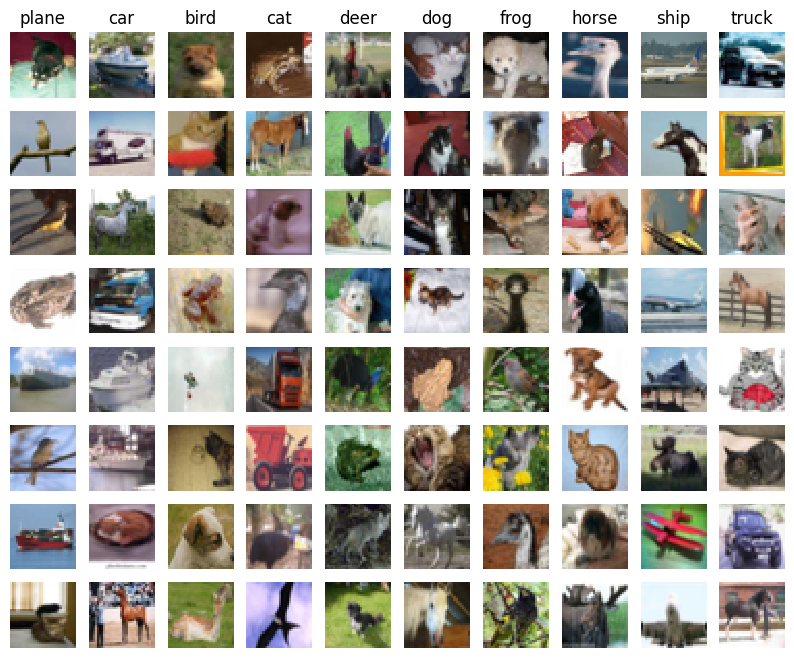

In [ ]:
# An important way to gain intuition about how an algorithm works is to
# visualize the mistakes that it makes. In this visualization, we show examples
# of images that are misclassified by our current system. The first column
# shows images that our system labeled as "plane" but whose true label is
# something other than "plane".

examples_per_class = 8
classes = ['plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
for cls, cls_name in enumerate(classes):
    idxs = np.where((y_test != cls) & (y_test_pred == cls))[0]
    idxs = np.random.choice(idxs, examples_per_class, replace=False)
    for i, idx in enumerate(idxs):
        plt.subplot(examples_per_class, len(classes), i * len(classes) + cls + 1)
        plt.imshow(X_test[idx].astype('uint8'))
        plt.axis('off')
        if i == 0:
            plt.title(cls_name)
plt.show()

### Inline question 1:
Describe the misclassification results that you see. Do they make sense?


$\color{blue}{\textit Your Answer:}$





## Neural Network on image features
Earlier in this assigment we saw that training a two-layer neural network on raw pixels achieved better classification performance than linear classifiers on raw pixels. In this notebook we have seen that linear classifiers on image features outperform linear classifiers on raw pixels.

For completeness, we should also try training a neural network on image features. This approach should outperform all previous approaches: you should easily be able to achieve over 55% classification accuracy on the test set; our best model achieves about 60% classification accuracy.

In [ ]:
# Preprocessing: Remove the bias dimension
# Make sure to run this cell only ONCE
print(X_train_feats.shape)
X_train_feats = X_train_feats[:, :-1]
X_val_feats = X_val_feats[:, :-1]
X_test_feats = X_test_feats[:, :-1]

print(X_train_feats.shape)

(49000, 170)
(49000, 169)


In [ ]:
from icv83551.classifiers.fc_net import TwoLayerNet
from icv83551.solver import Solver

input_dim = X_train_feats.shape[1]
hidden_dim = 500
num_classes = 10

data = {
    'X_train': X_train_feats,
    'y_train': y_train,
    'X_val': X_val_feats,
    'y_val': y_val,
    'X_test': X_test_feats,
    'y_test': y_test,
}

net = TwoLayerNet(input_dim, hidden_dim, num_classes)
best_net = None

################################################################################
# TODO: Train a two-layer neural network on image features. You may want to    #
# cross-validate various parameters as in previous sections. Store your best   #
# model in the best_net variable.                                              #
################################################################################
import numpy as np

# משתמשים ב-features שכבר חישבת למעלה
data_feats = {
    "X_train": X_train_feats,
    "y_train": y_train,
    "X_val": X_val_feats,
    "y_val": y_val,
    "X_test": X_test_feats,
    "y_test": y_test,
}

input_dim = X_train_feats.shape[1]
num_classes = int(np.max(y_train)) + 1

best_net = None
best_val = -1
best_params = None
results = {}

hidden_sizes = [100, 200, 400]
learning_rates = [1e-3, 3e-3]
regs = [0.0, 0.25, 0.5]

# 1) חיפוש קצר (5 epochs)
for hs in hidden_sizes:
    for lr in learning_rates:
        for reg in regs:
            net = TwoLayerNet(input_dim, hs, num_classes)
            net.reg = reg

            solver = Solver(
                net,
                data_feats,
                update_rule="adam",
                optim_config={"learning_rate": lr},
                lr_decay=0.95,
                num_epochs=5,
                batch_size=200,
                print_every=200,
                verbose=False,
            )
            solver.train()

            val_acc = solver.best_val_acc
            results[(hs, lr, reg)] = val_acc

            if val_acc > best_val:
                best_val = val_acc
                best_params = (hs, lr, reg)

            print("hs %d lr %e reg %e val %f" % (hs, lr, reg, val_acc))

print("best from sweep:", best_val, "params:", best_params)

# 2) אימון ארוך יותר עם הפרמטרים הכי טובים ושמירה ל-best_net
hs, lr, reg = best_params
best_net = TwoLayerNet(input_dim, hs, num_classes)
best_net.reg = reg

solver = Solver(
    best_net,
    data_feats,
    update_rule="adam",
    optim_config={"learning_rate": lr},
    lr_decay=0.95,
    num_epochs=15,
    batch_size=200,
    print_every=200,
    verbose=True,
)
solver.train()
best_net = solver.model

print("final best_val:", solver.best_val_acc)

hs 100 lr 1.000000e-03 reg 0.000000e+00 val 0.563000
hs 100 lr 1.000000e-03 reg 2.500000e-01 val 0.303000
hs 100 lr 1.000000e-03 reg 5.000000e-01 val 0.221000
hs 100 lr 3.000000e-03 reg 0.000000e+00 val 0.586000
hs 100 lr 3.000000e-03 reg 2.500000e-01 val 0.296000
hs 100 lr 3.000000e-03 reg 5.000000e-01 val 0.209000
hs 200 lr 1.000000e-03 reg 0.000000e+00 val 0.580000
hs 200 lr 1.000000e-03 reg 2.500000e-01 val 0.300000
hs 200 lr 1.000000e-03 reg 5.000000e-01 val 0.234000
hs 200 lr 3.000000e-03 reg 0.000000e+00 val 0.582000
hs 200 lr 3.000000e-03 reg 2.500000e-01 val 0.274000
hs 200 lr 3.000000e-03 reg 5.000000e-01 val 0.222000
hs 400 lr 1.000000e-03 reg 0.000000e+00 val 0.581000
hs 400 lr 1.000000e-03 reg 2.500000e-01 val 0.278000
hs 400 lr 1.000000e-03 reg 5.000000e-01 val 0.219000
hs 400 lr 3.000000e-03 reg 0.000000e+00 val 0.590000
hs 400 lr 3.000000e-03 reg 2.500000e-01 val 0.285000
hs 400 lr 3.000000e-03 reg 5.000000e-01 val 0.199000
best from sweep: 0.59 params: (400, 0.003, 0.0

In [ ]:
# Run your best neural net classifier on the test set. You should be able
# to get more than 58% accuracy. It is also possible to get >60% accuracy
# with careful tuning.

y_test_pred = np.argmax(best_net.loss(data['X_test']), axis=1)
test_acc = (y_test_pred == data['y_test']).mean()
print(test_acc)

0.583


In [ ]:
# Save best model
best_net.save("best_two_layer_net_features.npy")

best_two_layer_net_features.npy saved.
